# OpenCV and scikit-image library layer

This short tutorial runs one OpenCV function and one scikit-image function without creating a custom algorithm class.

## Follow along

Open this notebook in Jupyter and choose the Python environment where you installed Paidiverpy. Click a code cell and press **Shift+Enter** to run it. Results and messages appear below the cell. Start at the top, since later cells reuse names created earlier. If Python reports that a name is undefined, rerun the earlier cells. If it cannot find the YAML file, run the notebook from `examples/example_notebooks`.

1. Open [config_library.yml](../config_files/config_library.yml) in a text editor, then return here. YAML uses indentation to group settings. Under `general`, `sample_data: plankton_csv` selects the bundled example dataset. Under `steps`, each `- library:` starts one operation. Leave the indentation and the initial settings as shown for your first run.
2. In the first step, `name` is the label shown by Paidiverpy, `library: opencv` selects the package, and `function: GaussianBlur` selects the operation. `params` holds the function’s settings. `ksize` describes a 5 by 5 pixel window. `$tuple` converts the YAML list into a Python tuple, the fixed pair this example passes to OpenCV. `sigmaX` controls the blur along the horizontal axis.
3. The second step takes the OpenCV output and passes it to scikit-image. `filters.gaussian` means the `gaussian` function in the `filters` section of scikit-image. `sigma` controls the blur strength, `channel_axis: -1` says colour channels are stored on the last axis, and `preserve_range: true` keeps the original intensity scale.
4. Run the import cell, then the cell containing `config_path`, `Pipeline(...)`, and `.run()`. The first line identifies the YAML file, the second builds the pipeline, and the third runs it. Look for `Step 2 completed` after the image-opening step and the two filters. The sample can report missing metadata fields such as dates or depth. The blur steps do not use those fields.
5. Run the image preview and the array summary. Compare the three rows for opened images, OpenCV blur, and scikit-image blur. The filters should retain the image dimensions. A floating-point dtype after scikit-image means the pixels can contain fractional values.
6. Try one change in a copy of the YAML. Set scikit-image’s `sigma` to `3.0`, update `config_path` to your copy, and rerun the pipeline cell and the previews. Look for stronger smoothing. If the YAML cannot be found, check the working directory. If a function fails, start with the function name and image filename in the error message.

## Before you run

Use a Python kernel with Paidiverpy installed and run from `examples/example_notebooks` so `../config_files` resolves correctly. Run cells in order. Configurations using sample or remote data may need network access.

**Configuration:** `config_library.yml` in `../config_files`.

## What this example covers

Run OpenCV Gaussian blur followed by scikit-image Gaussian blur. The YAML passes a kernel tuple to OpenCV and sets `channel_axis: -1` for scikit-image.

## What to check

Inspect the raw and processed steps in `pipeline.images`. `preserve_range: true` retains the input intensity scale, and scikit-image can still return a floating-point array. If a function fails, use the filename and function name in the error to identify the input and check its dtype, channels, and arguments.

In [5]:
from paidiverpy.pipeline import Pipeline

The example configuration uses `$tuple` for OpenCV's kernel size, then calls `skimage.filters.gaussian`. Both functions receive every image automatically.

In [6]:
config_path = "../config_files/config_library.yml"
pipeline = Pipeline(config_file_path=config_path)
pipeline.run()

☁ paidiverpy ☁  |    WARNING | 2026-11-26 17:10:38 | Metadata does not have a datetime type column. It should have one of the following columns: ['datetime', 'date_time', 'DateTime', 'Datetime', 'image-datetime']. 

☁ paidiverpy ☁  |    WARNING | 2026-11-26 17:10:38 | Metadata does not have a datetime column
☁ paidiverpy ☁  |    WARNING | 2026-11-26 17:10:38 | Some functions may not work properly.
☁ paidiverpy ☁  |       INFO | 2026-11-26 17:10:38 | No dataset UUID found in the dataset metadata. A new UUID has been generated: 45db21d9-7dcb-4ade-a182-84bb7d146969
☁ paidiverpy ☁  |    WARNING | 2026-11-26 17:10:38 | Metadata does not have a camera-position type column. It should have one of the following columns: ['camera-position', 'camera_position', 'altitude_m', 'altitude_metre', 'altitude_meters', 'altitude_meter', 'image-altitude-meters']. 

☁ paidiverpy ☁  |    WARNING | 2026-11-26 17:10:38 | Metadata does not have a depth type column. It should have one of the following columns: [


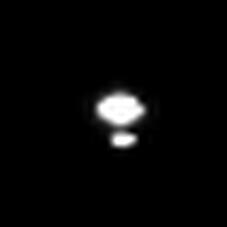
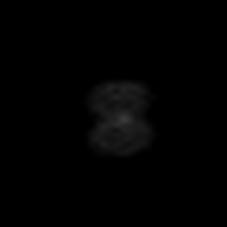
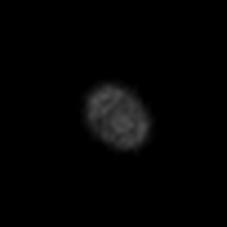
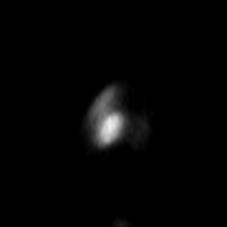
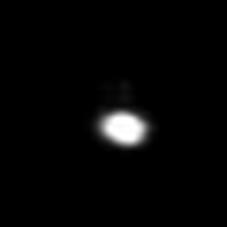
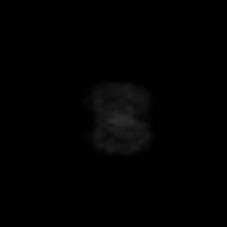
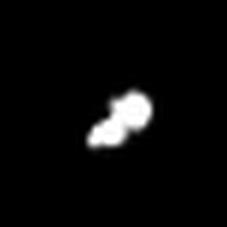
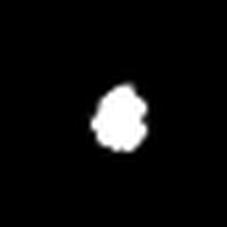
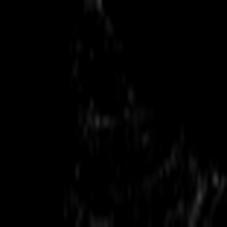
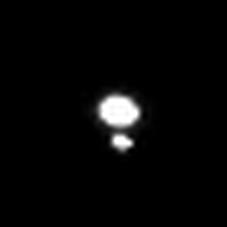
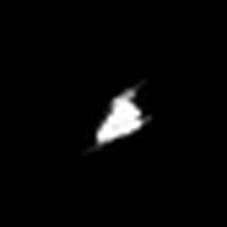
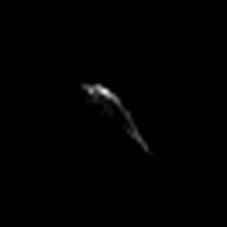
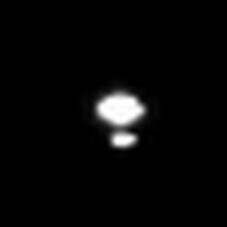
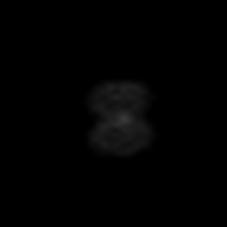
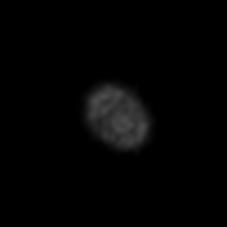
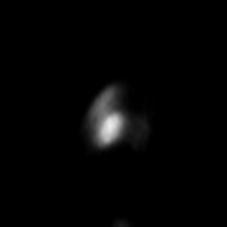
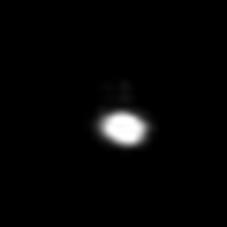
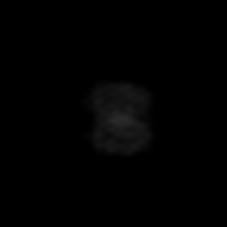
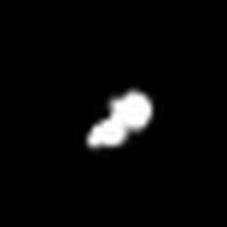
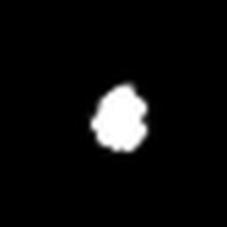
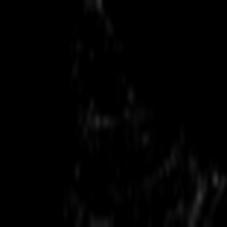
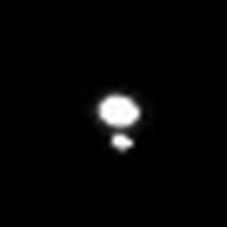
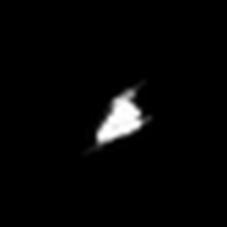
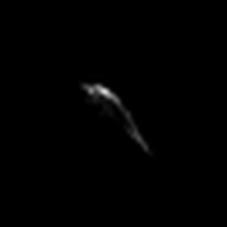
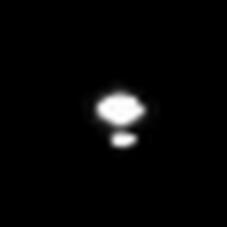
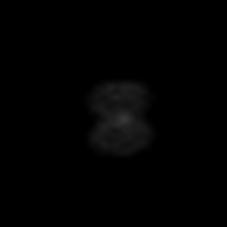
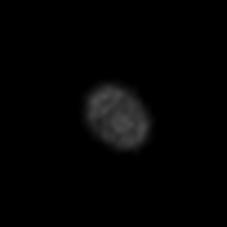
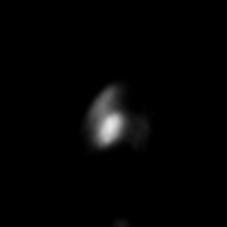
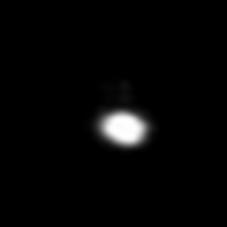
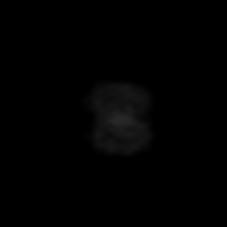
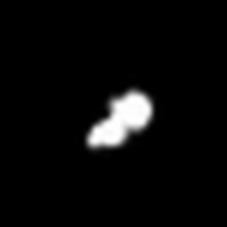
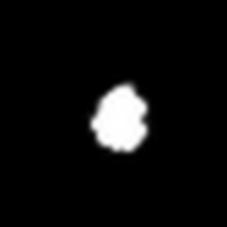
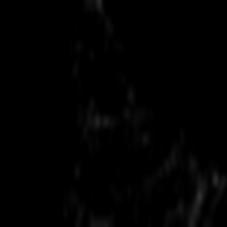
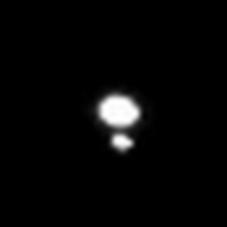
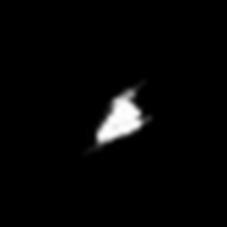
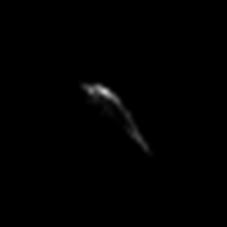

In [7]:
pipeline.images

## Compare the arrays

Inspect the stored arrays to see how each function affects image dimensions and dtype. The shape follows Paidiverpy’s xarray dimensions, so print the dimension names alongside it.

In [8]:
for index, label in enumerate(("Opened images", "OpenCV blur", "scikit-image blur")):
    images = pipeline.images.images[f"images_{index}"]
    print(label, dict(images.sizes), images.dtype)  # noqa: T201

Opened images {'filename': 58, 'y_0': 227, 'x_0': 227, 'band_0': 1} uint8
OpenCV blur {'filename': 58, 'y_1': 227, 'x_1': 227, 'band_1': 1} uint8
scikit-image blur {'filename': 58, 'y_2': 227, 'x_2': 227, 'band_2': 1} float64


Functions returning multiple values need `result_index`. For example, `cv2.threshold` returns `(threshold, image)`, so its configuration uses `result_index: 1`. Imported constants are represented as `{"$ref": "cv2.THRESH_BINARY"}`.